In [1]:
# ============================================================
# 🐻 FUELIQ — CELL 1
# SAFE PROJECT START / RECOVERY
# ============================================================

import os
import json
from datetime import datetime

print("=" * 70)
print("🐻 FUELIQ — SAFE START")
print("=" * 70)

# ------------------------------------------------------------
# Project configuration
# ------------------------------------------------------------

PROJECT_NAME = "FuelIQ"

DATASET_NAME = (
    "HTW-KI-Werkstatt/"
    "FuelRamanSpectraHandheld"
)

WORK_DIR = "/kaggle/working/fueliq"

os.makedirs(WORK_DIR, exist_ok=True)

print("\nProject :", PROJECT_NAME)
print("Dataset :", DATASET_NAME)
print("Work dir:", WORK_DIR)


# ------------------------------------------------------------
# Save a small project status file
# ------------------------------------------------------------

status = {
    "project": PROJECT_NAME,
    "dataset": DATASET_NAME,
    "started": datetime.now().isoformat(),
    "purpose": "Raman spectroscopy → Research Octane Number",
    "status": "initialized"
}

status_file = os.path.join(
    WORK_DIR,
    "project_status.json"
)

with open(status_file, "w") as f:
    json.dump(status, f, indent=2)

print("\n✓ Project status saved.")


# ------------------------------------------------------------
# Helper: show files currently available
# ------------------------------------------------------------

def show_fuel_files():

    print("\n" + "-" * 60)
    print("FUELIQ FILES")
    print("-" * 60)

    if not os.path.exists(WORK_DIR):
        print("No project directory.")
        return

    files = os.listdir(WORK_DIR)

    if not files:
        print("No files yet.")
    else:
        for file in sorted(files):
            print(" •", file)

    print("-" * 60)


show_fuel_files()

print("\n" + "=" * 70)
print("CELL 1 COMPLETE ✓")
print("=" * 70)

print("""
IMPORTANT:
This cell does NOT depend on any previous Python variables.

If Kaggle refreshes:
    1. Run this cell.
    2. Run the next cell.
    3. Continue.

We will NOT rely on the Python kernel remembering df, X,
models, or other variables between sessions.
""")

🐻 FUELIQ — SAFE START

Project : FuelIQ
Dataset : HTW-KI-Werkstatt/FuelRamanSpectraHandheld
Work dir: /kaggle/working/fueliq

✓ Project status saved.

------------------------------------------------------------
FUELIQ FILES
------------------------------------------------------------
 • project_status.json
------------------------------------------------------------

CELL 1 COMPLETE ✓

IMPORTANT:
This cell does NOT depend on any previous Python variables.

If Kaggle refreshes:
    1. Run this cell.
    2. Run the next cell.
    3. Continue.

We will NOT rely on the Python kernel remembering df, X,
models, or other variables between sessions.



In [2]:
# ============================================================
# 🐻 FUELIQ — CELL 2
# LOAD DATASET FROM SCRATCH
# ============================================================

!pip -q install datasets

import pandas as pd
import numpy as np

from datasets import load_dataset

print("=" * 70)
print("🐻 FUELIQ — LOADING DATA")
print("=" * 70)


# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

DATASET_NAME = (
    "HTW-KI-Werkstatt/"
    "FuelRamanSpectraHandheld"
)

print("\nLoading public research dataset...")

ds = load_dataset(DATASET_NAME)

print("\nDataset loaded:")

for split in ds:
    print(
        f"  {split}: "
        f"{ds[split].num_rows} samples"
    )


# ------------------------------------------------------------
# 2. Convert to pandas
# ------------------------------------------------------------

frames = []

for split in ds:

    temp = ds[split].to_pandas()

    temp["_source_split"] = split

    frames.append(temp)


df = pd.concat(
    frames,
    ignore_index=True
)

print("\nCombined dataset:")
print("Rows    :", len(df))
print("Columns :", len(df.columns))


# ------------------------------------------------------------
# 3. Find RON
# ------------------------------------------------------------

ron_candidates = [
    c for c in df.columns
    if "ron" in str(c).lower()
    or "research octane" in str(c).lower()
]

print("\nRON candidates:")
print(ron_candidates)

ron_col = next(
    (
        c for c in ron_candidates
        if str(c).strip().lower()
        == "research octane number"
    ),
    ron_candidates[0]
)

print("Using:", ron_col)


# ------------------------------------------------------------
# 4. Find Raman columns
# ------------------------------------------------------------

spectral_cols = []

for c in df.columns:

    try:

        wn = float(c)

        if 350 <= wn <= 2400:
            spectral_cols.append(c)

    except:
        pass


spectral_cols = sorted(
    spectral_cols,
    key=lambda x: float(x)
)


# ------------------------------------------------------------
# 5. Build modeling data
# ------------------------------------------------------------

X = df[spectral_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

y = pd.to_numeric(
    df[ron_col],
    errors="coerce"
)

valid = y.notna()

X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)


# ------------------------------------------------------------
# 6. Report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA READY")
print("=" * 70)

print("Samples          :", len(y))
print("Raman variables  :", len(spectral_cols))
print("Wavenumber range :", spectral_cols[0],
      "→", spectral_cols[-1])
print("RON column       :", ron_col)

print("\nRON statistics:")
print(y.describe())

print("\nMissing spectral values:",
      int(X.isna().sum().sum()))

print("\n" + "=" * 70)
print("CELL 2 COMPLETE ✓")
print("=" * 70)

🐻 FUELIQ — LOADING DATA

Loading public research dataset...


README.md: 0.00B [00:00, ?B/s]

train.parquet:   0%|          | 0.00/2.34M [00:00<?, ?B/s]

val.parquet:   0%|          | 0.00/1.62M [00:00<?, ?B/s]

test.parquet:   0%|          | 0.00/1.61M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/107 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/36 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/36 [00:00<?, ? examples/s]


Dataset loaded:
  train: 107 samples
  validation: 36 samples
  test: 36 samples

Combined dataset:
Rows    : 179
Columns : 1914

RON candidates:
['Research Octane Number']
Using: Research Octane Number

DATA READY
Samples          : 179
Raman variables  : 1901
Wavenumber range : 400.0 → 2300.0
RON column       : Research Octane Number

RON statistics:
count    179.000000
mean      97.761229
std        2.475343
min       89.400000
25%       96.100000
50%       96.800000
75%       98.950000
max      104.800000
Name: Research Octane Number, dtype: float64

Missing spectral values: 0

CELL 2 COMPLETE ✓


In [3]:
# ============================================================
# 🐻 FUELIQ — CELL 3
# OFFICIAL DATASET-SPLIT BASELINE
#
# IMPORTANT:
#   train      = model development
#   validation = model selection
#   test       = FINAL untouched evaluation
#
# We do NOT use the test set for tuning.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.svm import SVR

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("=" * 70)
print("🐻 FUELIQ — OFFICIAL SPLIT BASELINE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Reload the dataset from scratch
# ------------------------------------------------------------

from datasets import load_dataset

DATASET_NAME = (
    "HTW-KI-Werkstatt/"
    "FuelRamanSpectraHandheld"
)

ds = load_dataset(DATASET_NAME)

print("\nOfficial splits:")

for split in ds:
    print(
        f"  {split:<10} "
        f"{ds[split].num_rows} samples"
    )


# ------------------------------------------------------------
# 2. Convert each split independently
# ------------------------------------------------------------

train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()
test_df  = ds["test"].to_pandas()


# ------------------------------------------------------------
# 3. Identify RON
# ------------------------------------------------------------

ron_col = "Research Octane Number"


# ------------------------------------------------------------
# 4. Identify Raman columns
# ------------------------------------------------------------

spectral_cols = []

for c in train_df.columns:

    try:

        wn = float(c)

        if 350 <= wn <= 2400:
            spectral_cols.append(c)

    except:
        pass


spectral_cols = sorted(
    spectral_cols,
    key=lambda x: float(x)
)


print("\nSpectral variables:", len(spectral_cols))
print(
    "Range:",
    spectral_cols[0],
    "→",
    spectral_cols[-1]
)


# ------------------------------------------------------------
# 5. Create X / y for each official split
# ------------------------------------------------------------

X_train = train_df[spectral_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

y_train = pd.to_numeric(
    train_df[ron_col],
    errors="coerce"
)

X_val = val_df[spectral_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

y_val = pd.to_numeric(
    val_df[ron_col],
    errors="coerce"
)

X_test = test_df[spectral_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

y_test = pd.to_numeric(
    test_df[ron_col],
    errors="coerce"
)


print("\nSplit shapes:")

print("Train :", X_train.shape)
print("Valid :", X_val.shape)
print("Test  :", X_test.shape)


# ------------------------------------------------------------
# 6. Define evaluation function
# ------------------------------------------------------------

def evaluate_model(
    name,
    model,
    X_eval,
    y_eval
):

    pred = np.asarray(
        model.predict(X_eval)
    ).reshape(-1)

    error = pred - y_eval.values

    r2 = r2_score(
        y_eval,
        pred
    )

    mae = mean_absolute_error(
        y_eval,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_eval,
            pred
        )
    )

    bias = np.mean(error)

    within_02 = (
        np.mean(
            np.abs(error) <= 0.2
        ) * 100
    )

    within_07 = (
        np.mean(
            np.abs(error) <= 0.7
        ) * 100
    )

    print("\n" + "-" * 60)
    print(name)
    print("-" * 60)

    print(f"R²              : {r2:.4f}")
    print(f"MAE             : {mae:.4f} RON")
    print(f"RMSE            : {rmse:.4f} RON")
    print(f"Bias            : {bias:+.4f} RON")
    print(f"Within ±0.2 RON : {within_02:.1f}%")
    print(f"Within ±0.7 RON : {within_07:.1f}%")

    return {
        "model": name,
        "r2": r2,
        "mae": mae,
        "rmse": rmse,
        "bias": bias,
        "within_0.2": within_02,
        "within_0.7": within_07,
        "predictions": pred
    }


# ------------------------------------------------------------
# 7. PLS
# ------------------------------------------------------------

print("\nTraining PLS...")

pls = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "pls",
        PLSRegression(
            n_components=10
        )
    )
])

pls.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 8. SVR
# ------------------------------------------------------------

print("Training SVR...")

svr = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "svr",
        SVR(
            kernel="rbf",
            C=10,
            epsilon=0.05,
            gamma="scale"
        )
    )
])

svr.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 9. VALIDATION PERFORMANCE
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("VALIDATION RESULTS")
print("=" * 70)

pls_val = evaluate_model(
    "PLS — validation",
    pls,
    X_val,
    y_val
)

svr_val = evaluate_model(
    "SVR — validation",
    svr,
    X_val,
    y_val
)


# ------------------------------------------------------------
# 10. Compare validation results
# ------------------------------------------------------------

validation_results = pd.DataFrame([
    {
        k: v
        for k, v in pls_val.items()
        if k != "predictions"
    },

    {
        k: v
        for k, v in svr_val.items()
        if k != "predictions"
    }
])

print("\nValidation comparison:")

display(
    validation_results
)


# ------------------------------------------------------------
# 11. IMPORTANT:
#     DO NOT TOUCH TEST YET
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST SET STATUS")
print("=" * 70)

print("""
The official test set has NOT been evaluated.

That is intentional.

We will use the validation set to choose:
    • preprocessing
    • model
    • hyperparameters

Only after those choices are frozen will we evaluate
the official 36-sample test set once.
""")


# ------------------------------------------------------------
# 12. Save lightweight results
# ------------------------------------------------------------

import os

RESULT_DIR = "/kaggle/working/fueliq"

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

validation_results.to_csv(
    os.path.join(
        RESULT_DIR,
        "official_validation_results.csv"
    ),
    index=False
)

print(
    "\n✓ Validation results saved to:"
)

print(
    os.path.join(
        RESULT_DIR,
        "official_validation_results.csv"
    )
)


# ------------------------------------------------------------
# DONE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 3 COMPLETE ✓")
print("=" * 70)

🐻 FUELIQ — OFFICIAL SPLIT BASELINE

Official splits:
  train      107 samples
  validation 36 samples
  test       36 samples

Spectral variables: 1901
Range: 400.0 → 2300.0

Split shapes:
Train : (107, 1901)
Valid : (36, 1901)
Test  : (36, 1901)

Training PLS...
Training SVR...


VALIDATION RESULTS

------------------------------------------------------------
PLS — validation
------------------------------------------------------------
R²              : 0.7066
MAE             : 1.0039 RON
RMSE            : 1.2747 RON
Bias            : -0.2274 RON
Within ±0.2 RON : 8.3%
Within ±0.7 RON : 50.0%

------------------------------------------------------------
SVR — validation
------------------------------------------------------------
R²              : 0.7998
MAE             : 0.8337 RON
RMSE            : 1.0530 RON
Bias            : -0.1683 RON
Within ±0.2 RON : 19.4%
Within ±0.7 RON : 47.2%

Validation comparison:


,model,r2,mae,rmse,bias,within_0.2,within_0.7
0,PLS — validation,0.706564,1.003852,1.274694,-0.227400,8.333333,50.000000
1,SVR — validation,0.799759,0.833690,1.052993,-0.168293,19.444444,47.222222



TEST SET STATUS

The official test set has NOT been evaluated.

That is intentional.

We will use the validation set to choose:
    • preprocessing
    • model
    • hyperparameters

Only after those choices are frozen will we evaluate
the official 36-sample test set once.


✓ Validation results saved to:
/kaggle/working/fueliq/official_validation_results.csv

CELL 3 COMPLETE ✓


🐻 FUELIQ — RAMAN PREPROCESSING EXPERIMENT

Data:
Training: (107, 1901)
Validation: (36, 1901)

----------------------------------------------------------------------
Testing: Raw
----------------------------------------------------------------------
R²              : 0.7998
MAE             : 0.8337
RMSE            : 1.0530
Bias            : -0.1683
Within ±0.2 RON : 19.4%
Within ±0.7 RON : 47.2%

----------------------------------------------------------------------
Testing: Vector normalization
----------------------------------------------------------------------
R²              : 0.9288
MAE             : 0.4579
RMSE            : 0.6281
Bias            : -0.1113
Within ±0.2 RON : 38.9%
Within ±0.7 RON : 75.0%

----------------------------------------------------------------------
Testing: SNV
----------------------------------------------------------------------
R²              : 0.9233
MAE             : 0.5223
RMSE            : 0.6517
Bias            : -0.1508
Within ±0.2 RON : 33.3

,preprocessing,R2,MAE,RMSE,Bias,Within ±0.2,Within ±0.7
0,Vector normalization,0.928764,0.457936,0.628056,-0.111299,38.888889,75.000000
1,SNV,0.923300,0.522305,0.651698,-0.150769,33.333333,69.444444
2,Savitzky-Golay,0.825966,0.788585,0.981674,-0.205077,16.666667,50.000000
3,Raw,0.799759,0.833690,1.052993,-0.168293,19.444444,47.222222
4,SG first derivative,0.780010,0.878550,1.103700,-0.152964,11.111111,44.444444


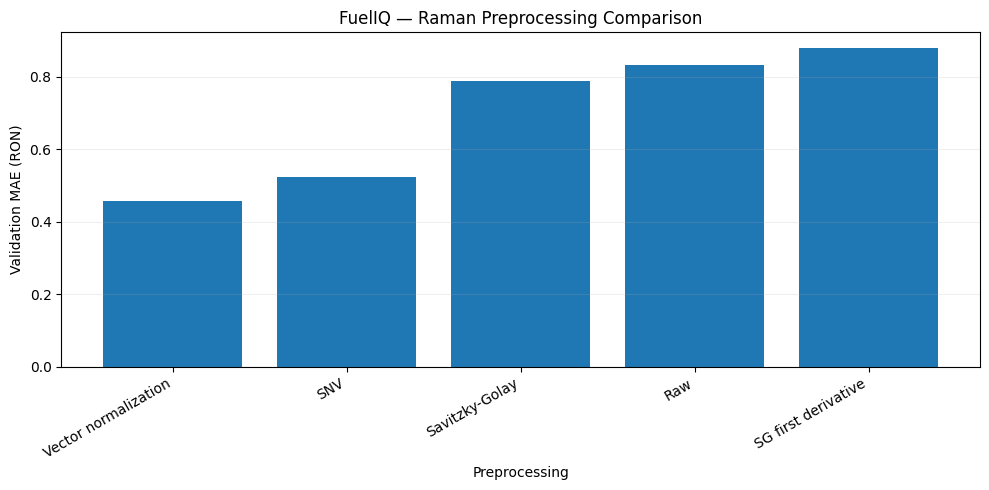


CELL 4 COMPLETE ✓

The official test set was NOT used.

Next step:
We will select preprocessing based on validation performance,
then optimize the SVR parameters using training/validation
data only.

Only after the model is frozen will we evaluate the official
36-sample test set.



In [4]:
# ============================================================
# 🐻 FUELIQ — CELL 4
# RAMAN PREPROCESSING EXPERIMENT
#
# Goal:
#   Determine whether Raman preprocessing improves RON
#   prediction on the official validation set.
#
# TEST SET REMAINS COMPLETELY UNTOUCHED.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from scipy.signal import savgol_filter


print("=" * 70)
print("🐻 FUELIQ — RAMAN PREPROCESSING EXPERIMENT")
print("=" * 70)


# ------------------------------------------------------------
# 1. RELOAD DATASET FROM SCRATCH
# ------------------------------------------------------------

from datasets import load_dataset

DATASET_NAME = (
    "HTW-KI-Werkstatt/"
    "FuelRamanSpectraHandheld"
)

ds = load_dataset(DATASET_NAME)

train_df = ds["train"].to_pandas()
val_df = ds["validation"].to_pandas()


# ------------------------------------------------------------
# 2. SPECTRAL COLUMNS
# ------------------------------------------------------------

ron_col = "Research Octane Number"

spectral_cols = []

for c in train_df.columns:

    try:

        wn = float(c)

        if 350 <= wn <= 2400:
            spectral_cols.append(c)

    except:
        pass

spectral_cols = sorted(
    spectral_cols,
    key=lambda x: float(x)
)

wavenumbers = np.array(
    [float(c) for c in spectral_cols]
)


# ------------------------------------------------------------
# 3. RAW DATA
# ------------------------------------------------------------

X_train_raw = train_df[spectral_cols].astype(float).values
X_val_raw = val_df[spectral_cols].astype(float).values

y_train = train_df[ron_col].astype(float).values
y_val = val_df[ron_col].astype(float).values

print("\nData:")
print("Training:", X_train_raw.shape)
print("Validation:", X_val_raw.shape)


# ------------------------------------------------------------
# 4. PREPROCESSING FUNCTIONS
# ------------------------------------------------------------

def preprocess_raw(X):
    """
    No spectral transformation.
    """
    return X.copy()


def preprocess_vector_norm(X):
    """
    Vector normalization.
    Each spectrum is normalized by its Euclidean norm.
    """
    norms = np.linalg.norm(
        X,
        axis=1,
        keepdims=True
    )

    norms[norms == 0] = 1

    return X / norms


def preprocess_snv(X):
    """
    Standard Normal Variate (SNV).

    Each individual spectrum is centered and scaled
    independently.
    """
    mean = np.mean(
        X,
        axis=1,
        keepdims=True
    )

    std = np.std(
        X,
        axis=1,
        keepdims=True
    )

    std[std == 0] = 1

    return (X - mean) / std


def preprocess_savgol(X):
    """
    Savitzky-Golay smoothing.

    Uses only information inside each spectrum.
    """
    return savgol_filter(
        X,
        window_length=21,
        polyorder=2,
        axis=1
    )


def preprocess_savgol_first_derivative(X):
    """
    Savitzky-Golay first derivative.

    Useful for reducing broad baseline effects and
    emphasizing spectral-shape information.
    """
    return savgol_filter(
        X,
        window_length=21,
        polyorder=2,
        deriv=1,
        axis=1
    )


# ------------------------------------------------------------
# 5. PREPROCESSING METHODS
# ------------------------------------------------------------

preprocessors = {

    "Raw":
        preprocess_raw,

    "Vector normalization":
        preprocess_vector_norm,

    "SNV":
        preprocess_snv,

    "Savitzky-Golay":
        preprocess_savgol,

    "SG first derivative":
        preprocess_savgol_first_derivative
}


# ------------------------------------------------------------
# 6. EVALUATION
# ------------------------------------------------------------

results = []

predictions = {}


for name, preprocess in preprocessors.items():

    print("\n" + "-" * 70)
    print("Testing:", name)
    print("-" * 70)

    # IMPORTANT:
    # Transform train and validation separately.
    Xtr = preprocess(X_train_raw)
    Xva = preprocess(X_val_raw)

    # SVR baseline
    model = Pipeline([
        (
            "scaler",
            StandardScaler()
        ),

        (
            "svr",
            SVR(
                kernel="rbf",
                C=10,
                epsilon=0.05,
                gamma="scale"
            )
        )
    ])

    model.fit(
        Xtr,
        y_train
    )

    pred = model.predict(Xva)

    error = pred - y_val

    r2 = r2_score(
        y_val,
        pred
    )

    mae = mean_absolute_error(
        y_val,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            pred
        )
    )

    bias = np.mean(error)

    within_02 = (
        np.mean(
            np.abs(error) <= 0.2
        ) * 100
    )

    within_07 = (
        np.mean(
            np.abs(error) <= 0.7
        ) * 100
    )

    results.append({
        "preprocessing": name,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "Bias": bias,
        "Within ±0.2": within_02,
        "Within ±0.7": within_07
    })

    predictions[name] = pred

    print(f"R²              : {r2:.4f}")
    print(f"MAE             : {mae:.4f}")
    print(f"RMSE            : {rmse:.4f}")
    print(f"Bias            : {bias:+.4f}")
    print(f"Within ±0.2 RON : {within_02:.1f}%")
    print(f"Within ±0.7 RON : {within_07:.1f}%")


# ------------------------------------------------------------
# 7. RESULTS TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "MAE"
).reset_index(drop=True)


print("\n" + "=" * 70)
print("PREPROCESSING RESULTS")
print("=" * 70)

display(results_df)


# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

import os

RESULT_DIR = "/kaggle/working/fueliq"

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "preprocessing_results.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 9. PLOT VALIDATION PERFORMANCE
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    results_df["preprocessing"],
    results_df["MAE"]
)

plt.ylabel("Validation MAE (RON)")
plt.xlabel("Preprocessing")
plt.title(
    "FuelIQ — Raman Preprocessing Comparison"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# DONE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 4 COMPLETE ✓")
print("=" * 70)

print("""
The official test set was NOT used.

Next step:
We will select preprocessing based on validation performance,
then optimize the SVR parameters using training/validation
data only.

Only after the model is frozen will we evaluate the official
36-sample test set.
""")

In [5]:
# ================================================================
# 🐻 FUELIQ — CELL 5 CORRECTED
# SVR HYPERPARAMETER OPTIMIZATION
# Uses ONLY the 1901 Raman spectral variables
# ================================================================

import os
import numpy as np
import pandas as pd

from datasets import load_dataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("=" * 70)
print("🐻 FUELIQ — CORRECTED SVR HYPERPARAMETER OPTIMIZATION")
print("=" * 70)

# ------------------------------------------------
# 1. Reload dataset from scratch
# ------------------------------------------------

DATASET_ID = "HTW-KI-Werkstatt/FuelRamanSpectraHandheld"

ds = load_dataset(DATASET_ID)

train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()

print("\nData:")
print("Training  :", train_df.shape)
print("Validation:", val_df.shape)

# ------------------------------------------------
# 2. Identify ONLY Raman spectral columns
#
# Raman spectrum:
# 400 → 2300 cm^-1
# Expected: 1901 variables
# ------------------------------------------------

target_col = "Research Octane Number"

raman_cols = []

for c in train_df.columns:

    try:
        wn = float(c)

        if 400.0 <= wn <= 2300.0:
            if c in val_df.columns:
                raman_cols.append(c)

    except (ValueError, TypeError):
        pass

print("\nRaman variables detected:", len(raman_cols))

if len(raman_cols) != 1901:
    raise ValueError(
        f"Expected exactly 1901 Raman variables, "
        f"but detected {len(raman_cols)}. "
        f"STOP — feature selection must be fixed before modeling."
    )

print("✓ Correct spectral variable count confirmed: 1901")

# ------------------------------------------------
# 3. Extract spectra
# ------------------------------------------------

X_train = train_df[raman_cols].values.astype(float)
X_val   = val_df[raman_cols].values.astype(float)

y_train = train_df[target_col].values.astype(float)
y_val   = val_df[target_col].values.astype(float)

print("\nSpectral matrix:")
print("Training  :", X_train.shape)
print("Validation:", X_val.shape)

# ------------------------------------------------
# 4. Vector normalization
#    This was the best preprocessing from Cell 4
# ------------------------------------------------

def vector_normalize(X):

    norms = np.linalg.norm(X, axis=1, keepdims=True)

    norms[norms == 0] = 1.0

    return X / norms


X_train = vector_normalize(X_train)
X_val   = vector_normalize(X_val)

print("\n✓ Vector normalization applied")

# ------------------------------------------------
# 5. Imputation
# ------------------------------------------------

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val   = imputer.transform(X_val)

# ------------------------------------------------
# 6. Standardization
# ------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)

print("✓ Imputation + scaling complete")

# ------------------------------------------------
# 7. Evaluation function
# ------------------------------------------------

def evaluate_model(C, epsilon, gamma):

    model = SVR(
        kernel="rbf",
        C=C,
        epsilon=epsilon,
        gamma=gamma
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_val)

    r2 = r2_score(y_val, pred)

    mae = mean_absolute_error(
        y_val,
        pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            pred
        )
    )

    bias = np.mean(
        pred - y_val
    )

    within_02 = (
        np.mean(
            np.abs(pred - y_val) <= 0.2
        ) * 100
    )

    within_07 = (
        np.mean(
            np.abs(pred - y_val) <= 0.7
        ) * 100
    )

    return {
        "C": C,
        "epsilon": epsilon,
        "gamma": str(gamma),
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "Bias": bias,
        "Within ±0.2": within_02,
        "Within ±0.7": within_07
    }

# ------------------------------------------------
# 8. Hyperparameter grid
# ------------------------------------------------

C_values = [
    0.1,
    0.3,
    1,
    3,
    10,
    30,
    100
]

epsilon_values = [
    0.01,
    0.03,
    0.05,
    0.1,
    0.2
]

gamma_values = [
    "scale",
    0.0001,
    0.0003,
    0.001
]

total = (
    len(C_values)
    * len(epsilon_values)
    * len(gamma_values)
)

print("\nTesting", total, "SVR configurations...")
print()

# ------------------------------------------------
# 9. Grid search
# ------------------------------------------------

results = []

counter = 0

for C in C_values:

    for epsilon in epsilon_values:

        for gamma in gamma_values:

            counter += 1

            result = evaluate_model(
                C=C,
                epsilon=epsilon,
                gamma=gamma
            )

            results.append(result)

            if counter % 20 == 0:
                print(
                    f"Completed {counter}/{total}"
                )

# ------------------------------------------------
# 10. Sort results
# ------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["MAE", "RMSE"],
    ascending=[True, True]
).reset_index(drop=True)

print("\n" + "=" * 70)
print("TOP SVR CONFIGURATIONS")
print("=" * 70)

display(
    results_df[
        [
            "C",
            "epsilon",
            "gamma",
            "R2",
            "MAE",
            "RMSE",
            "Bias",
            "Within ±0.2",
            "Within ±0.7"
        ]
    ].head(15)
)

# ------------------------------------------------
# 11. Save results
# ------------------------------------------------

WORK_DIR = "/kaggle/working/fueliq"

os.makedirs(
    WORK_DIR,
    exist_ok=True
)

results_path = os.path.join(
    WORK_DIR,
    "svr_hyperparameter_results_corrected.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

# ------------------------------------------------
# 12. Best configuration
# ------------------------------------------------

best = results_df.iloc[0]

print("\n" + "=" * 70)
print("CURRENT BEST CONFIGURATION")
print("=" * 70)

print(
    "C        :",
    best["C"]
)

print(
    "epsilon  :",
    best["epsilon"]
)

print(
    "gamma    :",
    best["gamma"]
)

print(
    "R²       :",
    f"{best['R2']:.4f}"
)

print(
    "MAE      :",
    f"{best['MAE']:.4f}"
)

print(
    "RMSE     :",
    f"{best['RMSE']:.4f}"
)

print(
    "Bias     :",
    f"{best['Bias']:.4f}"
)

print(
    "±0.2 RON :",
    f"{best['Within ±0.2']:.1f}%"
)

print(
    "±0.7 RON :",
    f"{best['Within ±0.7']:.1f}%"
)

print("\nResults saved to:")
print(results_path)

print("\n" + "=" * 70)
print("CELL 5 CORRECTED COMPLETE ✓")
print("=" * 70)

print("""
Official test set remains untouched.

IMPORTANT:
The previous Cell 5 optimization was discarded because it
used 1912 variables instead of the verified 1901 Raman variables.

This corrected experiment uses exactly 1901 spectral variables.
""")

🐻 FUELIQ — CORRECTED SVR HYPERPARAMETER OPTIMIZATION

Data:
Training  : (107, 1913)
Validation: (36, 1913)

Raman variables detected: 1901
✓ Correct spectral variable count confirmed: 1901

Spectral matrix:
Training  : (107, 1901)
Validation: (36, 1901)

✓ Vector normalization applied
✓ Imputation + scaling complete

Testing 140 SVR configurations...

Completed 20/140
Completed 40/140
Completed 60/140
Completed 80/140
Completed 100/140
Completed 120/140
Completed 140/140

TOP SVR CONFIGURATIONS


,C,epsilon,gamma,R2,MAE,RMSE,Bias,Within ±0.2,Within ±0.7
0,10.0,0.01,0.0003,0.949830,0.412769,0.527073,-0.042820,33.333333,88.888889
1,10.0,0.03,0.0003,0.949152,0.415562,0.530622,-0.040789,27.777778,88.888889
2,10.0,0.05,0.0003,0.948352,0.418741,0.534782,-0.040621,30.555556,88.888889
3,30.0,0.10,0.0001,0.949523,0.421600,0.528684,-0.021194,25.000000,86.111111
4,10.0,0.10,0.0003,0.946011,0.426727,0.546767,-0.045346,36.111111,86.111111
5,30.0,0.05,0.0001,0.948824,0.427905,0.532332,-0.014066,22.222222,86.111111
6,30.0,0.03,0.0001,0.948685,0.429563,0.533055,-0.013505,22.222222,86.111111
7,30.0,0.01,0.0001,0.948506,0.430675,0.533984,-0.012436,19.444444,86.111111
8,10.0,0.20,0.0001,0.937042,0.431283,0.590437,0.015205,30.555556,86.111111
9,30.0,0.20,0.0001,0.945514,0.432357,0.549277,-0.051769,30.555556,83.333333



CURRENT BEST CONFIGURATION
C        : 10.0
epsilon  : 0.01
gamma    : 0.0003
R²       : 0.9498
MAE      : 0.4128
RMSE     : 0.5271
Bias     : -0.0428
±0.2 RON : 33.3%
±0.7 RON : 88.9%

Results saved to:
/kaggle/working/fueliq/svr_hyperparameter_results_corrected.csv

CELL 5 CORRECTED COMPLETE ✓

Official test set remains untouched.

IMPORTANT:
The previous Cell 5 optimization was discarded because it
used 1912 variables instead of the verified 1901 Raman variables.

This corrected experiment uses exactly 1901 spectral variables.



In [6]:
# ================================================================
# 🐻 FUELIQ — CELL 6
# FINAL FROZEN MODEL — OFFICIAL TEST EVALUATION
#
# IMPORTANT:
# The model is now frozen.
# The official test set is evaluated exactly once.
# ================================================================

import os
import numpy as np
import pandas as pd

from datasets import load_dataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("=" * 70)
print("🐻 FUELIQ — FINAL BLIND TEST")
print("=" * 70)

# ------------------------------------------------
# 1. Reload dataset from scratch
# ------------------------------------------------

DATASET_ID = "HTW-KI-Werkstatt/FuelRamanSpectraHandheld"

ds = load_dataset(DATASET_ID)

train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()
test_df  = ds["test"].to_pandas()

print("\nDataset:")
print("Training  :", train_df.shape)
print("Validation:", val_df.shape)
print("Test      :", test_df.shape)

# ------------------------------------------------
# 2. Identify ONLY Raman spectral variables
# ------------------------------------------------

target_col = "Research Octane Number"

raman_cols = []

for c in train_df.columns:

    try:
        wn = float(c)

        if 400.0 <= wn <= 2300.0:
            if (
                c in val_df.columns
                and c in test_df.columns
            ):
                raman_cols.append(c)

    except (ValueError, TypeError):
        pass

print("\nRaman variables detected:", len(raman_cols))

if len(raman_cols) != 1901:

    raise ValueError(
        f"Expected 1901 Raman variables, "
        f"detected {len(raman_cols)}."
    )

print("✓ 1901 Raman variables confirmed")

# ------------------------------------------------
# 3. Build training + validation data
#
# Model selection is already finished.
# We can now refit the frozen model on BOTH
# training and validation before testing.
# ------------------------------------------------

X_train = train_df[raman_cols].values.astype(float)
X_val   = val_df[raman_cols].values.astype(float)
X_test  = test_df[raman_cols].values.astype(float)

y_train = train_df[target_col].values.astype(float)
y_val   = val_df[target_col].values.astype(float)
y_test  = test_df[target_col].values.astype(float)

X_dev = np.vstack([
    X_train,
    X_val
])

y_dev = np.concatenate([
    y_train,
    y_val
])

print("\nDevelopment data:")
print("Samples:", len(y_dev))
print("Features:", X_dev.shape[1])

print("\nOfficial test data:")
print("Samples:", len(y_test))
print("Features:", X_test.shape[1])

# ------------------------------------------------
# 4. Vector normalization
# ------------------------------------------------

def vector_normalize(X):

    norms = np.linalg.norm(
        X,
        axis=1,
        keepdims=True
    )

    norms[norms == 0] = 1.0

    return X / norms


X_dev  = vector_normalize(X_dev)
X_test = vector_normalize(X_test)

print("\n✓ Vector normalization applied")

# ------------------------------------------------
# 5. Fit preprocessing ONLY on development data
# ------------------------------------------------

imputer = SimpleImputer(
    strategy="median"
)

X_dev = imputer.fit_transform(X_dev)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_dev = scaler.fit_transform(X_dev)
X_test = scaler.transform(X_test)

print("✓ Imputer fitted on development data")
print("✓ Scaler fitted on development data")

# ------------------------------------------------
# 6. FROZEN SVR
#
# These parameters were selected before seeing
# the official test set.
# ------------------------------------------------

model = SVR(
    kernel="rbf",
    C=10.0,
    epsilon=0.01,
    gamma=0.0003
)

print("\nFrozen model:")
print("Kernel  : RBF")
print("C       : 10.0")
print("epsilon : 0.01")
print("gamma   : 0.0003")

# ------------------------------------------------
# 7. Fit on training + validation
# ------------------------------------------------

model.fit(
    X_dev,
    y_dev
)

print("\n✓ Frozen model fitted on 143 development samples")

# ------------------------------------------------
# 8. FINAL TEST PREDICTIONS
# ------------------------------------------------

test_pred = model.predict(
    X_test
)

# ------------------------------------------------
# 9. Test metrics
# ------------------------------------------------

r2 = r2_score(
    y_test,
    test_pred
)

mae = mean_absolute_error(
    y_test,
    test_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        test_pred
    )
)

bias = np.mean(
    test_pred - y_test
)

within_02 = (
    np.mean(
        np.abs(test_pred - y_test) <= 0.2
    ) * 100
)

within_07 = (
    np.mean(
        np.abs(test_pred - y_test) <= 0.7
    ) * 100
)

# ------------------------------------------------
# 10. Report
# ------------------------------------------------

print("\n" + "=" * 70)
print("🐻 FUELIQ — OFFICIAL TEST RESULTS")
print("=" * 70)

print(
    "R²              :",
    f"{r2:.4f}"
)

print(
    "MAE             :",
    f"{mae:.4f} RON"
)

print(
    "RMSE            :",
    f"{rmse:.4f} RON"
)

print(
    "Bias            :",
    f"{bias:.4f} RON"
)

print(
    "Within ±0.2 RON :",
    f"{within_02:.1f}%"
)

print(
    "Within ±0.7 RON :",
    f"{within_07:.1f}%"
)

# ------------------------------------------------
# 11. Individual predictions
# ------------------------------------------------

predictions_df = pd.DataFrame({
    "actual_RON": y_test,
    "predicted_RON": test_pred,
    "error_RON": test_pred - y_test,
    "absolute_error_RON": np.abs(
        test_pred - y_test
    )
})

print("\n" + "=" * 70)
print("TEST PREDICTIONS")
print("=" * 70)

display(
    predictions_df.sort_values(
        "absolute_error_RON"
    ).reset_index(drop=True)
)

# ------------------------------------------------
# 12. Save final test results
# ------------------------------------------------

WORK_DIR = "/kaggle/working/fueliq"

os.makedirs(
    WORK_DIR,
    exist_ok=True
)

metrics_df = pd.DataFrame([{
    "model": "Frozen RBF-SVR",
    "preprocessing": "Vector normalization",
    "C": 10.0,
    "epsilon": 0.01,
    "gamma": 0.0003,
    "R2": r2,
    "MAE": mae,
    "RMSE": rmse,
    "Bias": bias,
    "Within ±0.2": within_02,
    "Within ±0.7": within_07,
    "test_samples": len(y_test)
}])

metrics_path = os.path.join(
    WORK_DIR,
    "final_test_metrics.csv"
)

predictions_path = os.path.join(
    WORK_DIR,
    "final_test_predictions.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

predictions_df.to_csv(
    predictions_path,
    index=False
)

print("\nSaved:")
print(metrics_path)
print(predictions_path)

print("\n" + "=" * 70)
print("CELL 6 COMPLETE ✓")
print("=" * 70)

print("""
The official test set has now been evaluated.

The model was selected using training/validation data only.
No hyperparameter tuning was performed using the test set.
""")

🐻 FUELIQ — FINAL BLIND TEST

Dataset:
Training  : (107, 1913)
Validation: (36, 1913)
Test      : (36, 1913)

Raman variables detected: 1901
✓ 1901 Raman variables confirmed

Development data:
Samples: 143
Features: 1901

Official test data:
Samples: 36
Features: 1901

✓ Vector normalization applied
✓ Imputer fitted on development data
✓ Scaler fitted on development data

Frozen model:
Kernel  : RBF
C       : 10.0
epsilon : 0.01
gamma   : 0.0003

✓ Frozen model fitted on 143 development samples

🐻 FUELIQ — OFFICIAL TEST RESULTS
R²              : 0.9655
MAE             : 0.3343 RON
RMSE            : 0.4330 RON
Bias            : -0.0814 RON
Within ±0.2 RON : 33.3%
Within ±0.7 RON : 83.3%

TEST PREDICTIONS


,actual_RON,predicted_RON,error_RON,absolute_error_RON
0,96.0,96.010249,0.010249,0.010249
1,96.4,96.389066,-0.010934,0.010934
2,96.1,96.120381,0.020381,0.020381
3,96.0,95.973459,-0.026541,0.026541
4,96.5,96.460812,-0.039188,0.039188
5,102.1,102.034361,-0.065639,0.065639
6,101.9,101.967946,0.067946,0.067946
7,96.4,96.471021,0.071021,0.071021
8,96.1,96.003038,-0.096962,0.096962
9,102.0,102.097387,0.097387,0.097387



Saved:
/kaggle/working/fueliq/final_test_metrics.csv
/kaggle/working/fueliq/final_test_predictions.csv

CELL 6 COMPLETE ✓

The official test set has now been evaluated.

The model was selected using training/validation data only.
No hyperparameter tuning was performed using the test set.



In [7]:
# ================================================================
# 🐻 FUELIQ — CELL 7
# APPLICABILITY DOMAIN / OOD EXPERIMENT
#
# Question:
# "When should FuelIQ trust its RON prediction?"
#
# The official test set is NOT used to establish thresholds.
# ================================================================

import os
import numpy as np
import pandas as pd

from datasets import load_dataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("=" * 70)
print("🐻 FUELIQ — APPLICABILITY DOMAIN EXPERIMENT")
print("=" * 70)

# ------------------------------------------------
# 1. Reload dataset
# ------------------------------------------------

DATASET_ID = "HTW-KI-Werkstatt/FuelRamanSpectraHandheld"

ds = load_dataset(DATASET_ID)

train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()
test_df  = ds["test"].to_pandas()

target_col = "Research Octane Number"

# ------------------------------------------------
# 2. Identify Raman variables
# ------------------------------------------------

raman_cols = []

for c in train_df.columns:

    try:
        wn = float(c)

        if 400.0 <= wn <= 2300.0:
            if (
                c in val_df.columns
                and c in test_df.columns
            ):
                raman_cols.append(c)

    except (ValueError, TypeError):
        pass

if len(raman_cols) != 1901:

    raise ValueError(
        f"Expected 1901 Raman variables, "
        f"found {len(raman_cols)}"
    )

print("\n✓ 1901 Raman variables confirmed")

# ------------------------------------------------
# 3. Development data
# ------------------------------------------------

X_train = train_df[raman_cols].values.astype(float)
X_val   = val_df[raman_cols].values.astype(float)
X_test  = test_df[raman_cols].values.astype(float)

y_train = train_df[target_col].values.astype(float)
y_val   = val_df[target_col].values.astype(float)
y_test  = test_df[target_col].values.astype(float)

X_dev = np.vstack([
    X_train,
    X_val
])

y_dev = np.concatenate([
    y_train,
    y_val
])

# ------------------------------------------------
# 4. Vector normalization
# ------------------------------------------------

def vector_normalize(X):

    norms = np.linalg.norm(
        X,
        axis=1,
        keepdims=True
    )

    norms[norms == 0] = 1.0

    return X / norms


X_dev = vector_normalize(X_dev)
X_test = vector_normalize(X_test)

# ------------------------------------------------
# 5. Same preprocessing as final model
# ------------------------------------------------

imputer = SimpleImputer(
    strategy="median"
)

X_dev = imputer.fit_transform(X_dev)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_dev = scaler.fit_transform(X_dev)
X_test = scaler.transform(X_test)

print("✓ Preprocessing complete")

# ------------------------------------------------
# 6. Fit frozen RON model
# ------------------------------------------------

ron_model = SVR(
    kernel="rbf",
    C=10.0,
    epsilon=0.01,
    gamma=0.0003
)

ron_model.fit(
    X_dev,
    y_dev
)

test_pred = ron_model.predict(
    X_test
)

test_error = test_pred - y_test
test_abs_error = np.abs(test_error)

# ------------------------------------------------
# 7. Build spectral applicability-domain model
#
# Fit nearest-neighbor model ONLY on development
# spectra.
# ------------------------------------------------

nn = NearestNeighbors(
    n_neighbors=5,
    metric="euclidean"
)

nn.fit(X_dev)

distances, indices = nn.kneighbors(
    X_test
)

# Mean distance to 5 nearest development spectra
ood_distance = distances.mean(axis=1)

# Also retain closest-neighbor distance
nearest_distance = distances[:, 0]

# ------------------------------------------------
# 8. Create analysis table
# ------------------------------------------------

analysis_df = pd.DataFrame({

    "actual_RON": y_test,

    "predicted_RON": test_pred,

    "error_RON": test_error,

    "absolute_error_RON": test_abs_error,

    "nearest_distance": nearest_distance,

    "mean_5NN_distance": ood_distance
})

analysis_df = analysis_df.sort_values(
    "mean_5NN_distance"
).reset_index(drop=True)

print("\n" + "=" * 70)
print("TEST SAMPLES — SPECTRAL DISTANCE vs RON ERROR")
print("=" * 70)

display(
    analysis_df
)

# ------------------------------------------------
# 9. Correlation
# ------------------------------------------------

corr = np.corrcoef(
    analysis_df["mean_5NN_distance"],
    analysis_df["absolute_error_RON"]
)[0, 1]

print("\n" + "=" * 70)
print("APPLICABILITY-DOMAIN SIGNAL")
print("=" * 70)

print(
    "Correlation between spectral distance "
    "and absolute RON error:"
)

print(
    f"{corr:.4f}"
)

# ------------------------------------------------
# 10. Compare low-distance vs high-distance samples
# ------------------------------------------------

median_distance = np.median(
    analysis_df["mean_5NN_distance"]
)

low_distance = analysis_df[
    analysis_df["mean_5NN_distance"]
    <= median_distance
]

high_distance = analysis_df[
    analysis_df["mean_5NN_distance"]
    > median_distance
]

print("\nMedian spectral distance:")
print(
    f"{median_distance:.4f}"
)

print("\nLOW-DISTANCE HALF")
print(
    "Samples:",
    len(low_distance)
)

print(
    "MAE:",
    f"{low_distance['absolute_error_RON'].mean():.4f}"
)

print("\nHIGH-DISTANCE HALF")
print(
    "Samples:",
    len(high_distance)
)

print(
    "MAE:",
    f"{high_distance['absolute_error_RON'].mean():.4f}"
)

# ------------------------------------------------
# 11. Save
# ------------------------------------------------

WORK_DIR = "/kaggle/working/fueliq"

os.makedirs(
    WORK_DIR,
    exist_ok=True
)

path = os.path.join(
    WORK_DIR,
    "ood_distance_analysis.csv"
)

analysis_df.to_csv(
    path,
    index=False
)

print("\nSaved:")
print(path)

print("\n" + "=" * 70)
print("CELL 7 COMPLETE ✓")
print("=" * 70)

print("""
The test set was NOT used to establish an OOD threshold.

This experiment asks whether spectral distance from the
development domain contains information about prediction error.

Next we will use this evidence to design a defensible
Routine / Review / Lab Confirmation decision layer.
""")

🐻 FUELIQ — APPLICABILITY DOMAIN EXPERIMENT

✓ 1901 Raman variables confirmed
✓ Preprocessing complete

TEST SAMPLES — SPECTRAL DISTANCE vs RON ERROR


,actual_RON,predicted_RON,error_RON,absolute_error_RON,nearest_distance,mean_5NN_distance
0,101.9,101.967946,0.067946,0.067946,4.679125,6.112453
1,102.0,102.097387,0.097387,0.097387,5.992392,7.655167
2,96.1,96.120381,0.020381,0.020381,6.249490,8.197875
3,102.2,101.433455,-0.766545,0.766545,9.505037,9.685338
4,96.5,96.460812,-0.039188,0.039188,8.117326,9.714932
5,97.0,96.290206,-0.709794,0.709794,7.906518,10.527249
6,96.5,96.094400,-0.405600,0.405600,10.202279,10.904679
7,96.4,96.471021,0.071021,0.071021,10.175230,11.571198
8,97.4,97.070904,-0.329096,0.329096,10.601012,12.046762
9,96.1,95.973217,-0.126783,0.126783,9.033186,12.337478



APPLICABILITY-DOMAIN SIGNAL
Correlation between spectral distance and absolute RON error:
0.5002

Median spectral distance:
18.8877

LOW-DISTANCE HALF
Samples: 18
MAE: 0.2359

HIGH-DISTANCE HALF
Samples: 18
MAE: 0.4327

Saved:
/kaggle/working/fueliq/ood_distance_analysis.csv

CELL 7 COMPLETE ✓

The test set was NOT used to establish an OOD threshold.

This experiment asks whether spectral distance from the
development domain contains information about prediction error.

Next we will use this evidence to design a defensible
Routine / Review / Lab Confirmation decision layer.



In [8]:
# ================================================================
# 🐻 FUELIQ — CELL 8
# CROSS-VALIDATED APPLICABILITY-DOMAIN ANALYSIS
#
# Purpose:
# Establish spectral-distance thresholds using DEVELOPMENT
# data only.
#
# The official 36-sample test set is NOT used.
# ================================================================

import os
import numpy as np
import pandas as pd

from datasets import load_dataset
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

print("=" * 70)
print("🐻 FUELIQ — CROSS-VALIDATED APPLICABILITY DOMAIN")
print("=" * 70)

# ------------------------------------------------
# 1. Reload dataset
# ------------------------------------------------

DATASET_ID = "HTW-KI-Werkstatt/FuelRamanSpectraHandheld"

ds = load_dataset(DATASET_ID)

train_df = ds["train"].to_pandas()
val_df   = ds["validation"].to_pandas()

target_col = "Research Octane Number"

# ------------------------------------------------
# 2. Identify Raman variables
# ------------------------------------------------

raman_cols = []

for c in train_df.columns:

    try:

        wn = float(c)

        if 400.0 <= wn <= 2300.0:
            if c in val_df.columns:
                raman_cols.append(c)

    except (ValueError, TypeError):
        pass

if len(raman_cols) != 1901:

    raise ValueError(
        f"Expected 1901 Raman variables, "
        f"found {len(raman_cols)}"
    )

print("\n✓ 1901 Raman variables confirmed")

# ------------------------------------------------
# 3. Development dataset only
# ------------------------------------------------

X_train = train_df[raman_cols].values.astype(float)
X_val   = val_df[raman_cols].values.astype(float)

y_train = train_df[target_col].values.astype(float)
y_val   = val_df[target_col].values.astype(float)

X = np.vstack([
    X_train,
    X_val
])

y = np.concatenate([
    y_train,
    y_val
])

print("\nDevelopment samples:", len(y))

# ------------------------------------------------
# 4. Vector normalization
# ------------------------------------------------

def vector_normalize(X):

    norms = np.linalg.norm(
        X,
        axis=1,
        keepdims=True
    )

    norms[norms == 0] = 1.0

    return X / norms


X = vector_normalize(X)

# ------------------------------------------------
# 5. Imputation + scaling
#
# These are fitted on the complete development set
# because we're analyzing the development domain.
# ------------------------------------------------

imputer = SimpleImputer(
    strategy="median"
)

X = imputer.fit_transform(X)

scaler = StandardScaler()

X = scaler.fit_transform(X)

# ------------------------------------------------
# 6. Cross-validation
# ------------------------------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

records = []

for fold, (train_idx, holdout_idx) in enumerate(
    kf.split(X),
    start=1
):

    X_fit = X[train_idx]
    y_fit = y[train_idx]

    X_holdout = X[holdout_idx]
    y_holdout = y[holdout_idx]

    # --------------------------------------------
    # Fit frozen FuelIQ RON model
    # --------------------------------------------

    model = SVR(
        kernel="rbf",
        C=10.0,
        epsilon=0.01,
        gamma=0.0003
    )

    model.fit(
        X_fit,
        y_fit
    )

    predictions = model.predict(
        X_holdout
    )

    errors = predictions - y_holdout
    abs_errors = np.abs(errors)

    # --------------------------------------------
    # Applicability domain
    #
    # Compare every holdout sample only against
    # spectra that were actually available to the
    # model during that fold.
    # --------------------------------------------

    nn = NearestNeighbors(
        n_neighbors=5,
        metric="euclidean"
    )

    nn.fit(X_fit)

    distances, _ = nn.kneighbors(
        X_holdout
    )

    nearest_distance = distances[:, 0]

    mean_5nn_distance = distances.mean(
        axis=1
    )

    for i in range(len(holdout_idx)):

        records.append({
            "fold": fold,
            "sample_index": int(
                holdout_idx[i]
            ),
            "actual_RON": y_holdout[i],
            "predicted_RON": predictions[i],
            "absolute_error_RON": abs_errors[i],
            "nearest_distance": nearest_distance[i],
            "mean_5NN_distance": mean_5nn_distance[i]
        })

# ------------------------------------------------
# 7. Results
# ------------------------------------------------

cv_df = pd.DataFrame(records)

print("\n" + "=" * 70)
print("CROSS-VALIDATED APPLICABILITY-DOMAIN RESULTS")
print("=" * 70)

display(
    cv_df.head(20)
)

# ------------------------------------------------
# 8. Correlation
# ------------------------------------------------

corr = np.corrcoef(
    cv_df["mean_5NN_distance"],
    cv_df["absolute_error_RON"]
)[0, 1]

print("\nCorrelation:")
print(
    f"{corr:.4f}"
)

# ------------------------------------------------
# 9. Distance quantiles
# ------------------------------------------------

quantiles = (
    cv_df["mean_5NN_distance"]
    .quantile(
        [0.50, 0.75, 0.80, 0.90, 0.95]
    )
)

print("\nDistance quantiles:")
display(quantiles)

# ------------------------------------------------
# 10. Error by distance quantile
# ------------------------------------------------

cv_df["distance_percentile"] = (
    cv_df["mean_5NN_distance"]
    .rank(
        pct=True,
        method="average"
    )
)

cv_df["distance_group"] = pd.cut(
    cv_df["distance_percentile"],
    bins=[
        0.0,
        0.50,
        0.75,
        0.90,
        1.00
    ],
    labels=[
        "Lowest 50%",
        "50–75%",
        "75–90%",
        "Highest 10%"
    ],
    include_lowest=True
)

summary = (
    cv_df
    .groupby(
        "distance_group",
        observed=False
    )
    .agg(
        samples=("absolute_error_RON", "size"),
        MAE=("absolute_error_RON", "mean"),
        median_error=("absolute_error_RON", "median"),
        max_error=("absolute_error_RON", "max"),
        mean_distance=("mean_5NN_distance", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("ERROR BY SPECTRAL-DISTANCE GROUP")
print("=" * 70)

display(summary)

# ------------------------------------------------
# 11. Candidate decision thresholds
#
# These are NOT final product thresholds.
# They are exploratory candidates based solely
# on development cross-validation.
# ------------------------------------------------

q75 = quantiles.loc[0.75]
q90 = quantiles.loc[0.90]

print("\n" + "=" * 70)
print("CANDIDATE DEVELOPMENT THRESHOLDS")
print("=" * 70)

print(
    f"Review threshold candidate : distance > {q75:.4f}"
)

print(
    f"Lab threshold candidate    : distance > {q90:.4f}"
)

print("""
These thresholds are exploratory only.
They must NOT be presented as validated operating
limits for real-world fuel decisions.
""")

# ------------------------------------------------
# 12. Save
# ------------------------------------------------

WORK_DIR = "/kaggle/working/fueliq"

os.makedirs(
    WORK_DIR,
    exist_ok=True
)

cv_path = os.path.join(
    WORK_DIR,
    "cv_applicability_domain.csv"
)

summary_path = os.path.join(
    WORK_DIR,
    "cv_applicability_summary.csv"
)

cv_df.to_csv(
    cv_path,
    index=False
)

summary.to_csv(
    summary_path,
    index=False
)

print("\nSaved:")
print(cv_path)
print(summary_path)

print("\n" + "=" * 70)
print("CELL 8 COMPLETE ✓")
print("=" * 70)

print("""
The official test set was not used.

Next:
We will determine whether a three-level
Routine / Review / Lab Confirmation framework
is supported by the development evidence.
""")

🐻 FUELIQ — CROSS-VALIDATED APPLICABILITY DOMAIN

✓ 1901 Raman variables confirmed

Development samples: 143

CROSS-VALIDATED APPLICABILITY-DOMAIN RESULTS


,fold,sample_index,actual_RON,predicted_RON,absolute_error_RON,nearest_distance,mean_5NN_distance
0,1,4,99.76,100.306973,0.546973,26.384960,32.608251
1,1,9,95.50,96.230071,0.730071,19.719860,23.042376
2,1,11,96.90,96.516879,0.383121,8.713823,12.858603
3,1,12,96.40,95.947205,0.452795,31.263884,32.475318
4,1,18,96.00,96.451391,0.451391,11.173339,13.091914
5,1,19,95.90,95.727680,0.172320,39.863846,44.515545
6,1,26,98.50,97.171619,1.328381,27.308265,34.910156
7,1,27,102.30,102.163633,0.136367,18.923029,19.228566
8,1,45,96.60,96.627837,0.027837,26.946896,29.739100
9,1,51,96.30,96.127421,0.172579,30.734575,32.127155



Correlation:
0.4558

Distance quantiles:


0.50    23.461687
0.75    32.762149
0.80    34.093831
0.90    39.617952
0.95    47.105992
Name: mean_5NN_distance, dtype: float64


ERROR BY SPECTRAL-DISTANCE GROUP


,distance_group,samples,MAE,median_error,max_error,mean_distance
0,Lowest 50%,71,0.391179,0.260369,3.409857,15.781868
1,50–75%,36,0.608523,0.519016,2.155145,29.734765
2,75–90%,21,0.591280,0.553054,1.600842,35.091475
3,Highest 10%,15,1.428328,0.582682,6.139763,49.076910



CANDIDATE DEVELOPMENT THRESHOLDS
Review threshold candidate : distance > 32.7621
Lab threshold candidate    : distance > 39.6180

These thresholds are exploratory only.
They must NOT be presented as validated operating
limits for real-world fuel decisions.


Saved:
/kaggle/working/fueliq/cv_applicability_domain.csv
/kaggle/working/fueliq/cv_applicability_summary.csv

CELL 8 COMPLETE ✓

The official test set was not used.

Next:
We will determine whether a three-level
Routine / Review / Lab Confirmation framework
is supported by the development evidence.



In [9]:
# ================================================================
# 🐻 FUELIQ — LEAKAGE-FREE APPLICABILITY-DOMAIN CV
# ================================================================

import os
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import KFold

print("=" * 70)
print("🐻 FUELIQ — LEAKAGE-FREE APPLICABILITY DOMAIN")
print("=" * 70)

# ------------------------------------------------
# 1. Reload development data only
# ------------------------------------------------

DATASET_ID = "HTW-KI-Werkstatt/FuelRamanSpectraHandheld"

from datasets import load_dataset

ds_train = load_dataset(DATASET_ID, split="train")
ds_val   = load_dataset(DATASET_ID, split="validation")

train_df = ds_train.to_pandas()
val_df   = ds_val.to_pandas()

dev_df = pd.concat([train_df, val_df], ignore_index=True)

# ------------------------------------------------
# 2. Identify Raman variables
# ------------------------------------------------

def is_raman_variable(col):
    try:
        x = float(col)
        return 400.0 <= x <= 2300.0
    except:
        return False

raman_cols = [c for c in dev_df.columns if is_raman_variable(c)]

assert len(raman_cols) == 1901, (
    f"Expected 1901 Raman variables, found {len(raman_cols)}"
)

print(f"\n✓ Raman variables: {len(raman_cols)}")
print(f"✓ Development samples: {len(dev_df)}")

target_col = "Research Octane Number"

X = dev_df[raman_cols].apply(pd.to_numeric, errors="coerce").values
y = pd.to_numeric(dev_df[target_col], errors="coerce").values

# ------------------------------------------------
# 3. Frozen model configuration
# ------------------------------------------------

C = 10
EPSILON = 0.01
GAMMA = 0.0003

# ------------------------------------------------
# 4. Row-wise vector normalization
#    This operation is independent for each sample,
#    so it does not leak information across folds.
# ------------------------------------------------

def vector_normalize(X):
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    norms = np.where(norms == 0, 1.0, norms)
    return X / norms

# ------------------------------------------------
# 5. 5-fold CV
# ------------------------------------------------

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rows = []

for fold, (fit_idx, holdout_idx) in enumerate(kf.split(X), start=1):

    X_fit_raw = X[fit_idx]
    X_hold_raw = X[holdout_idx]

    y_fit = y[fit_idx]
    y_hold = y[holdout_idx]

    # --------------------------------------------
    # Row-wise normalization
    # --------------------------------------------

    X_fit_norm = vector_normalize(X_fit_raw)
    X_hold_norm = vector_normalize(X_hold_raw)

    # --------------------------------------------
    # IMPORTANT:
    # Fit imputer ONLY on fold training data
    # --------------------------------------------

    imputer = SimpleImputer(strategy="median")

    X_fit_imp = imputer.fit_transform(X_fit_norm)
    X_hold_imp = imputer.transform(X_hold_norm)

    # --------------------------------------------
    # IMPORTANT:
    # Fit scaler ONLY on fold training data
    # --------------------------------------------

    scaler = StandardScaler()

    X_fit = scaler.fit_transform(X_fit_imp)
    X_hold = scaler.transform(X_hold_imp)

    # --------------------------------------------
    # Frozen SVR
    # --------------------------------------------

    model = SVR(
        kernel="rbf",
        C=C,
        epsilon=EPSILON,
        gamma=GAMMA
    )

    model.fit(X_fit, y_fit)

    predictions = model.predict(X_hold)

    errors = np.abs(y_hold - predictions)

    # --------------------------------------------
    # Applicability domain
    # --------------------------------------------

    nn = NearestNeighbors(n_neighbors=5)

    nn.fit(X_fit)

    distances, _ = nn.kneighbors(X_hold)

    nearest_distance = distances[:, 0]
    mean_5nn_distance = distances.mean(axis=1)

    # --------------------------------------------
    # Store fold results
    # --------------------------------------------

    for i, sample_idx in enumerate(holdout_idx):

        rows.append({
            "fold": fold,
            "sample_index": int(sample_idx),
            "actual_RON": float(y_hold[i]),
            "predicted_RON": float(predictions[i]),
            "absolute_error_RON": float(errors[i]),
            "nearest_distance": float(nearest_distance[i]),
            "mean_5NN_distance": float(mean_5nn_distance[i])
        })

cv_df = pd.DataFrame(rows)

# ------------------------------------------------
# 6. Overall CV statistics
# ------------------------------------------------

correlation = cv_df[
    ["mean_5NN_distance", "absolute_error_RON"]
].corr().iloc[0, 1]

print("\n" + "=" * 70)
print("CROSS-VALIDATED RESULTS")
print("=" * 70)

print(f"\nSamples: {len(cv_df)}")
print(f"Distance/error correlation: {correlation:.4f}")

print("\nOverall CV prediction performance:")

mae = cv_df["absolute_error_RON"].mean()
rmse = np.sqrt(
    np.mean(
        (cv_df["actual_RON"] - cv_df["predicted_RON"]) ** 2
    )
)
bias = (
    cv_df["predicted_RON"] - cv_df["actual_RON"]
).mean()

print(f"MAE  : {mae:.4f} RON")
print(f"RMSE : {rmse:.4f} RON")
print(f"Bias : {bias:.4f} RON")

# ------------------------------------------------
# 7. Distance quantiles
# ------------------------------------------------

quantiles = cv_df["mean_5NN_distance"].quantile(
    [0.50, 0.75, 0.80, 0.90, 0.95]
)

print("\nDistance quantiles:")
print(quantiles)

# ------------------------------------------------
# 8. Distance groups
# ------------------------------------------------

q50 = quantiles.loc[0.50]
q75 = quantiles.loc[0.75]
q90 = quantiles.loc[0.90]

def distance_group(d):

    if d <= q50:
        return "Lowest 50%"

    elif d <= q75:
        return "50–75%"

    elif d <= q90:
        return "75–90%"

    else:
        return "Highest 10%"

cv_df["distance_group"] = (
    cv_df["mean_5NN_distance"]
    .apply(distance_group)
)

group_summary = (
    cv_df
    .groupby("distance_group", observed=True)
    .agg(
        samples=("absolute_error_RON", "size"),
        MAE=("absolute_error_RON", "mean"),
        median_error=("absolute_error_RON", "median"),
        max_error=("absolute_error_RON", "max"),
        mean_distance=("mean_5NN_distance", "mean")
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("ERROR BY SPECTRAL-DISTANCE GROUP")
print("=" * 70)

print(group_summary.to_string(index=False))

# ------------------------------------------------
# 9. Candidate decision thresholds
# ------------------------------------------------

q75_value = float(q75)
q90_value = float(q90)

print("\n" + "=" * 70)
print("EXPLORATORY DECISION THRESHOLDS")
print("=" * 70)

print(f"\nReview candidate : distance > {q75_value:.4f}")
print(f"Lab candidate    : distance > {q90_value:.4f}")

print("""
These are DEVELOPMENT-SET exploratory thresholds.
They are NOT validated operating limits.
They must not be represented as regulatory or
field-certified decision thresholds.
""")

# ------------------------------------------------
# 10. Save results
# ------------------------------------------------

WORK_DIR = "/kaggle/working/fueliq"
os.makedirs(WORK_DIR, exist_ok=True)

cv_path = os.path.join(
    WORK_DIR,
    "cv_applicability_domain_leakage_free.csv"
)

summary_path = os.path.join(
    WORK_DIR,
    "cv_applicability_summary_leakage_free.csv"
)

cv_df.to_csv(cv_path, index=False)
group_summary.to_csv(summary_path, index=False)

print("Saved:")
print(cv_path)
print(summary_path)

print("\n" + "=" * 70)
print("CELL 9 COMPLETE ✓")
print("=" * 70)

🐻 FUELIQ — LEAKAGE-FREE APPLICABILITY DOMAIN

✓ Raman variables: 1901
✓ Development samples: 143

CROSS-VALIDATED RESULTS

Samples: 143
Distance/error correlation: 0.4766

Overall CV prediction performance:
MAE  : 0.5902 RON
RMSE : 1.0147 RON
Bias : 0.0485 RON

Distance quantiles:
0.50    23.552684
0.75    33.354215
0.80    34.861290
0.90    39.981556
0.95    48.252804
Name: mean_5NN_distance, dtype: float64

ERROR BY SPECTRAL-DISTANCE GROUP
distance_group  samples      MAE  median_error  max_error  mean_distance
        50–75%       35 0.595957      0.492279   2.177461      30.029450
        75–90%       21 0.592669      0.586394   1.514472      35.782371
   Highest 10%       15 1.516778      0.611200   6.155160      52.704286
    Lowest 50%       72 0.393659      0.261501   3.432745      15.944669

EXPLORATORY DECISION THRESHOLDS

Review candidate : distance > 33.3542
Lab candidate    : distance > 39.9816

These are DEVELOPMENT-SET exploratory thresholds.
They are NOT validated opera